In [ ]:
import numpy as np
print(np.__version__, np.__file__)
print(hasattr(np, "subtract"))

2.5.4 c:\Users\manue\.conda\envs\gis\Lib\site-packages\numpy\__init__.py
True


In [ ]:
# !pip install geopandas pandas matplotlib mapclassify requests
from pathlib import Path
from datetime import date

import pandas as pd
import numpy as np
import geopandas as gpd

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.colors import LogNorm, TwoSlopeNorm, Normalize
from matplotlib.cm import ScalarMappable

IN_PATH = Path("../data/external")

OUT = Path("../outputs")
OUT.mkdir(exist_ok=True)         # crea la carpeta de salida si no existe

In [ ]:
data_path = IN_PATH / f"eu-ets{date.today().strftime('%d-%m-%Y')}.csv"

if not data_path.exists():
    url = "https://datahub.io/core/eu-emissions-trading-system/r/eu-ets.csv"
    df = pd.read_csv(url)
    df.to_csv(data_path, index=False)
else:
    df = pd.read_csv(data_path)

print(df.columns.tolist())
df.head()

['country_code', 'main_activity_code', 'main_activity_name', 'citl_information', 'year', 'value']


,country_code,main_activity_code,main_activity_name,citl_information,year,value
0,AT,10,10 Aviation,1. Total allocated allowances (EUA or EUAA),2005,0.0
1,AT,20,20 Combustion of fuels,1. Total allocated allowances (EUA or EUAA),2005,14362552.0
2,AT,20-99,20-99 All stationary installations,1. Total allocated allowances (EUA or EUAA),2005,32412654.0
3,AT,21,21 Refining of mineral oil,1. Total allocated allowances (EUA or EUAA),2005,2720740.0
4,AT,21-99,21-99 All industrial installations (excl. comb...,1. Total allocated allowances (EUA or EUAA),2005,18050102.0


In [ ]:
print(df["citl_information"].unique())

['1. Total allocated allowances (EUA or EUAA)'
 '1.1 Freely allocated allowances'
 '1.1.1 Free allocation to existing entities (Art. 10a(1))'
 '1.1.2 Free allocation from the new entrants reserve (Art. 10a(7))'
 '1.1.4 Swiss Free Allocated allowances for aircraft operators'
 '1.2 Correction to freely allocated allowances (not reflected in EUTL)'
 '1.3 Allowances auctioned or sold (EUAs and EUAAs)'
 '2. Verified emissions' '2.1 EU-ETS Verified Emission'
 '2.1b EU-ETS Verified Emissions (expected, gap-filled for latest year)'
 '2.2 Swiss Verified Emissions for aircraft operators'
 '3. Estimate to reflect current ETS scope for allowances and emissions'
 '4. Total surrendered units'
 '4.1 Surrendered EU allowances (EUAs and EUAAs)'
 '4.2 Surrendered certified emission reductions (CERs)'
 '4.3 Surrendered emission reduction units (ERUs)'
 '4.4 Surrendered Units CHU/CHUAA'
 '2.1c Gap-fill increment (gap-filled minus reported, latest year)'
 '1.1.3 Free allocation for modernisation of electri

In [ ]:
print(df["main_activity_code"].unique())

['10' '20' '20-99' '21' '21-99' '22' '24' '29' '30' '31' '32' '35' '36'
 '42' '99' '38' '25' '27' '28' '34' '41' '43' '26' '33' '37' '50' '44'
 '23' '39' '40' '45']


In [ ]:
print(df["year"].unique())

['2005' '2006' '2007' '2008' '2009' '2010' '2011' '2012' '2013' '2014'
 '2015' '2016' '2017' '2018' '2019' '2020' '2021' '2022' '2023' '2024'
 '2025' 'Total 1st trading period (05-07)'
 'Total 2nd trading period (08-12)' 'Total 3rd trading period (13-20)'
 'Total 4th trading period (21-30)']


In [ ]:
print(df["country_code"].unique())

['AT' 'BE' 'BG' 'CY' 'CZ' 'DE' 'DK' 'EE' 'ES' 'FI' 'FR' 'GB' 'GR' 'HR'
 'HU' 'IE' 'IS' 'IT' 'Innovation fund' 'LI' 'LT' 'LU' 'LV' 'MT'
 'Modernisation Fund' 'NER 300 auctions' 'NL' 'NO' 'PL' 'PT' 'RO' 'RRF'
 'SE' 'SI' 'SK' 'XI']


In [ ]:
YEAR = "2023"   # ajusta según lo que veas en df["year"].unique()

ver = df[
    df["citl_information"].str.contains("Verified emissions", case=False, na=False)
    & (df["year"].astype(str) == YEAR)
]

# Instalaciones fijas (agregado oficial, sin doble conteo)
stationary = (
    ver[ver["main_activity_code"].astype(str) == "20-99"]
    .groupby("country_code", as_index=False)["value"].sum()
    .rename(columns={"value": "stationary"})
)

# Aviación (opcional)
aviation = (
    ver[ver["main_activity_code"].astype(str) == "10"]
    .groupby("country_code", as_index=False)["value"].sum()
    .rename(columns={"value": "aviation"})
)

emis = stationary.merge(aviation, on="country_code", how="left").fillna(0)
emis["total"] = emis["stationary"] + emis["aviation"]
emis["value_mt"] = emis["total"] / 1e6   # millones de t CO2e
emis.sort_values("value_mt", ascending=False).head(10)

,country_code,stationary,aviation,total,value_mt
5,DE,289340809.0,7795855.0,297136664.0,297.136664
23,PL,153018903.0,976058.0,153994961.0,153.994961
16,IT,114784026.0,2562231.0,117346257.0,117.346257
8,ES,81133557.0,8049971.0,89183528.0,89.183528
10,FR,70652409.0,3209197.0,73861606.0,73.861606
21,NL,58888869.0,2726333.0,61615202.0,61.615202
4,CZ,46672102.0,263938.0,46936040.0,46.936040
1,BE,35402662.0,1072000.0,36474662.0,36.474662
0,AT,24413340.0,3313347.0,27726687.0,27.726687
11,GR,25466136.0,1368235.0,26834371.0,26.834371


In [ ]:
gisco = "https://gisco-services.ec.europa.eu/distribution/v2/countries/geojson/CNTR_RG_20M_2020_4326.geojson"
world = gpd.read_file(gisco)

# GISCO usa EL para Grecia; el CSV probablemente usa GR
emis["country_code"] = emis["country_code"].replace({"GR": "EL"})

In [ ]:
europe = world.merge(emis, left_on="CNTR_ID", right_on="country_code", how="left").to_crs(3035)

# Países del CSV que no encontraron polígono
print(set(emis["country_code"]) - set(world["CNTR_ID"]))

set()


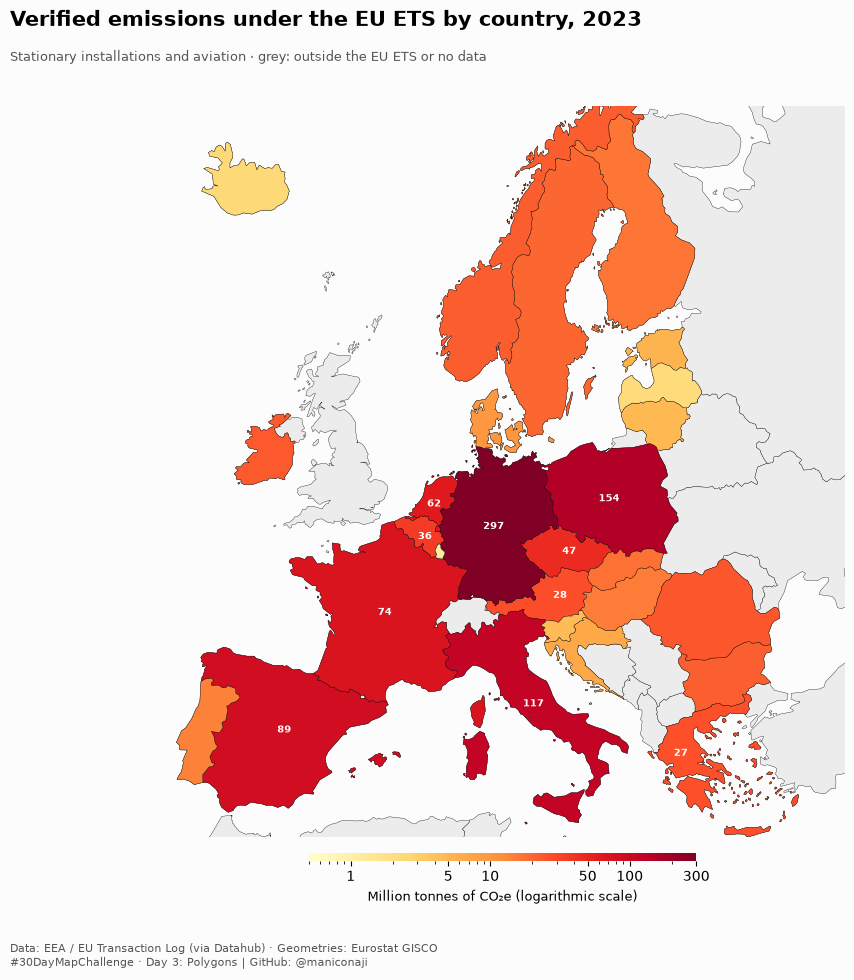

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10), facecolor="#FCFCFC")

norm = LogNorm(vmin=0.5, vmax=300)
cmap = "YlOrRd"

# Background: countries without data
europe.plot(ax=ax, color="#ececec", edgecolor="k", linewidth=0.25)

# Countries with data
data = europe.dropna(subset=["value_mt"])
data.plot(
    column="value_mt", 
    ax=ax, 
    cmap=cmap, 
    norm=norm,
    edgecolor="k", 
    linewidth=0.25)

# Labels: top 10 emitters
top = data.nlargest(10, "value_mt").copy()
top["pt"] = top.geometry.representative_point()
for _, r in top.iterrows():
    ax.annotate(
        f"{r['value_mt']:.0f}", xy=(r["pt"].x, r["pt"].y),
        ha="center", 
        va="center", 
        fontsize=7.5,
        fontweight="bold", 
        color="white")

# Compact colorbar
sm = ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(
    sm, 
    ax=ax, 
    orientation="horizontal",
    fraction=0.03, 
    pad=0.02, 
    shrink=0.5, 
    aspect=50)
cbar.set_ticks([1, 5, 10, 50, 100, 300])
cbar.set_ticklabels(["1", "5", "10", "50", "100", "300"])
cbar.set_label("Million tonnes of CO₂e (logarithmic scale)", fontsize=9)
cbar.outline.set_visible(False)

# Map extent
ax.set_xlim(2.55e6, 6.2e6)
ax.set_ylim(1.45e6, 5.35e6)
ax.set_axis_off()

# Title and subtitle, aligned to the same anchor
fig.text(
    0.02, 0.96, 
    "Verified emissions under the EU ETS by country, 2023",
    ha="left", 
    fontsize=15, 
    fontweight="bold")
fig.text(
    0.02, 0.925, 
    "Stationary installations and aviation · grey: outside the EU ETS or no data",
    ha="left", 
    fontsize=9.5, 
    color="#555")

fig.text(
    0.02, 0.02,
    "Data: EEA / EU Transaction Log (via Datahub) · Geometries: Eurostat GISCO\n"
    "#30DayMapChallenge · Day 3: Polygons | GitHub: @maniconaji",
    fontsize=8, 
    color="#555")

plt.savefig(OUT / "day03_polygons_en.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [ ]:
CAT_VERIFIED = "2. Verified emissions"
CAT_FILLED = "2.1b EU-ETS Verified Emissions (expected, gap-filled for latest year)"

def stationary_emissions(year, category=CAT_VERIFIED):
    sel = df[
        (df["citl_information"] == category)
        & (df["year"].astype(str) == year)
        & (df["main_activity_code"].astype(str) == "20-99")
    ]
    return sel.groupby("country_code")["value"].sum()

# Comprobación: Alemania 2025 con cada categoría (Mt)
for cat in (CAT_VERIFIED, CAT_FILLED):
    print(cat[:30], round(stationary_emissions("2025", cat).get("DE", float("nan")) / 1e6, 1))

BASE_YEAR = "2005"
END_YEAR = "2025"
END_CAT = CAT_FILLED if END_YEAR == "2025" else CAT_VERIFIED   # gap-filled solo para el último año

base = stationary_emissions(BASE_YEAR)
end = stationary_emissions(END_YEAR, END_CAT)

change = pd.DataFrame({"base": base, "end": end}).dropna()
change = change[change["base"] > 0]
change["pct"] = (change["end"] / change["base"] - 1) * 100
change = change.reset_index()
change["country_code"] = change["country_code"].replace({"GR": "EL"})

print(change.sort_values("pct")[["country_code", "pct"]].round(1).to_string(index=False))

europe_chg = world.merge(change, left_on="CNTR_ID", right_on="country_code", how="left").to_crs(3035)

2. Verified emissions 263.6
2.1b EU-ETS Verified Emissions 265.3
country_code   pct
          DK -70.2
          PT -68.7
          EE -67.3
          FI -64.1
          EL -63.7
          MT -63.5
          XI -63.3
          LU -62.6
          SI -57.9
          ES -57.3
          HU -57.1
          IT -55.1
          FR -53.4
          IE -52.5
          CZ -51.4
          DE -44.1
          SK -42.0
          LV -41.8
          BE -34.8
          LT -30.2
          PL -28.2
          AT -23.3
          NL -23.0
          SE -16.5
          CY -14.7


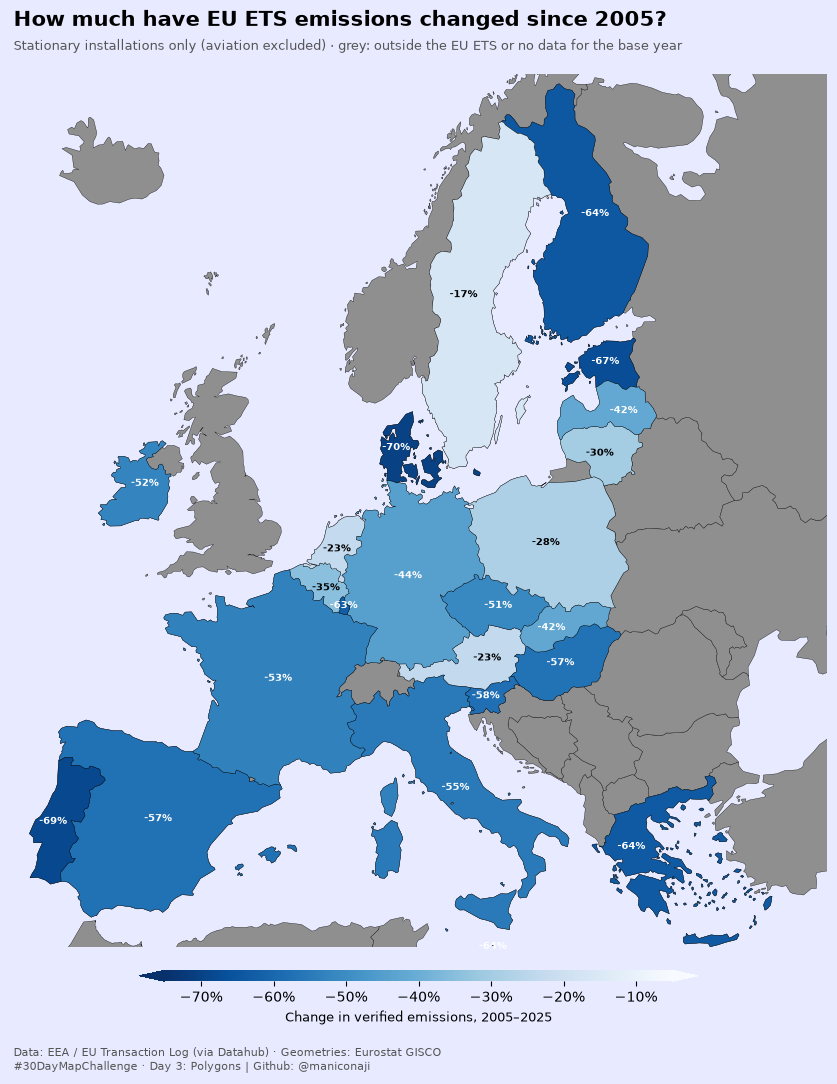

In [ ]:
# ---- Map ----
fig, ax = plt.subplots(figsize=(12, 12), facecolor="#E8EBFF")

norm = Normalize(vmin=-75, vmax=-5)   # ajusta según los datos que veas
cmap = "Blues_r"                                      # azul = reducción, rojo = aumento

# Background: countries without data
europe_chg.plot(ax=ax, color="#8F8F8F", edgecolor="k", linewidth=0.25)
data = europe_chg.dropna(subset=["pct"])
data.plot(
    column="pct", 
    ax=ax, 
    cmap=cmap, 
    norm=norm,
    edgecolor="k", 
    linewidth=0.25)

# Labels for the 12 largest emitters in the end year
top = data.copy() # data.nlargest(12, "end")
top["pt"] = top.geometry.representative_point()
for _, r in top.iterrows():
    if r['pct'] < -40:
        ax.annotate(
            f"{r['pct']:+.0f}%", xy=(r["pt"].x, r["pt"].y),
            ha="center", va="center", fontsize=7,
            fontweight="bold", color="#FFFFFF")
    else:
        ax.annotate(
            f"{r['pct']:+.0f}%", xy=(r["pt"].x, r["pt"].y),
            ha="center", va="center", fontsize=7,
            fontweight="bold", color="#000000")

sm = ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(
    sm, ax=ax, orientation="horizontal",
    fraction=0.03, pad=0.025, shrink=0.60, aspect=50, extend="both")
ticks = [-70, -60, -50, -40, -30, -20, -10]
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t}%".replace("-", "−") for t in ticks])
cbar.set_label(f"Change in verified emissions, {BASE_YEAR}–{END_YEAR}", fontsize=9)
cbar.outline.set_visible(False)

ax.set_xlim(2.55e6, 6.2e6)
ax.set_ylim(1.45e6, 5.35e6)
ax.set_axis_off()

fig.text(
    0.175, 0.92,
    f"How much have EU ETS emissions changed since {BASE_YEAR}?", 
    ha="left", fontsize=15, fontweight="bold")
fig.text(
    0.175, 0.90,
    "Stationary installations only (aviation excluded) · grey: outside the EU ETS or no data for the base year",
    ha="left", fontsize=9.5, color="#555")
fig.text(
    0.175, 0.05,
    "Data: EEA / EU Transaction Log (via Datahub) · Geometries: Eurostat GISCO\n"
    "#30DayMapChallenge · Day 3: Polygons | Github: @maniconaji",
    fontsize=8, color="#555")

plt.savefig(OUT / "day03_polygons_change.png", dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

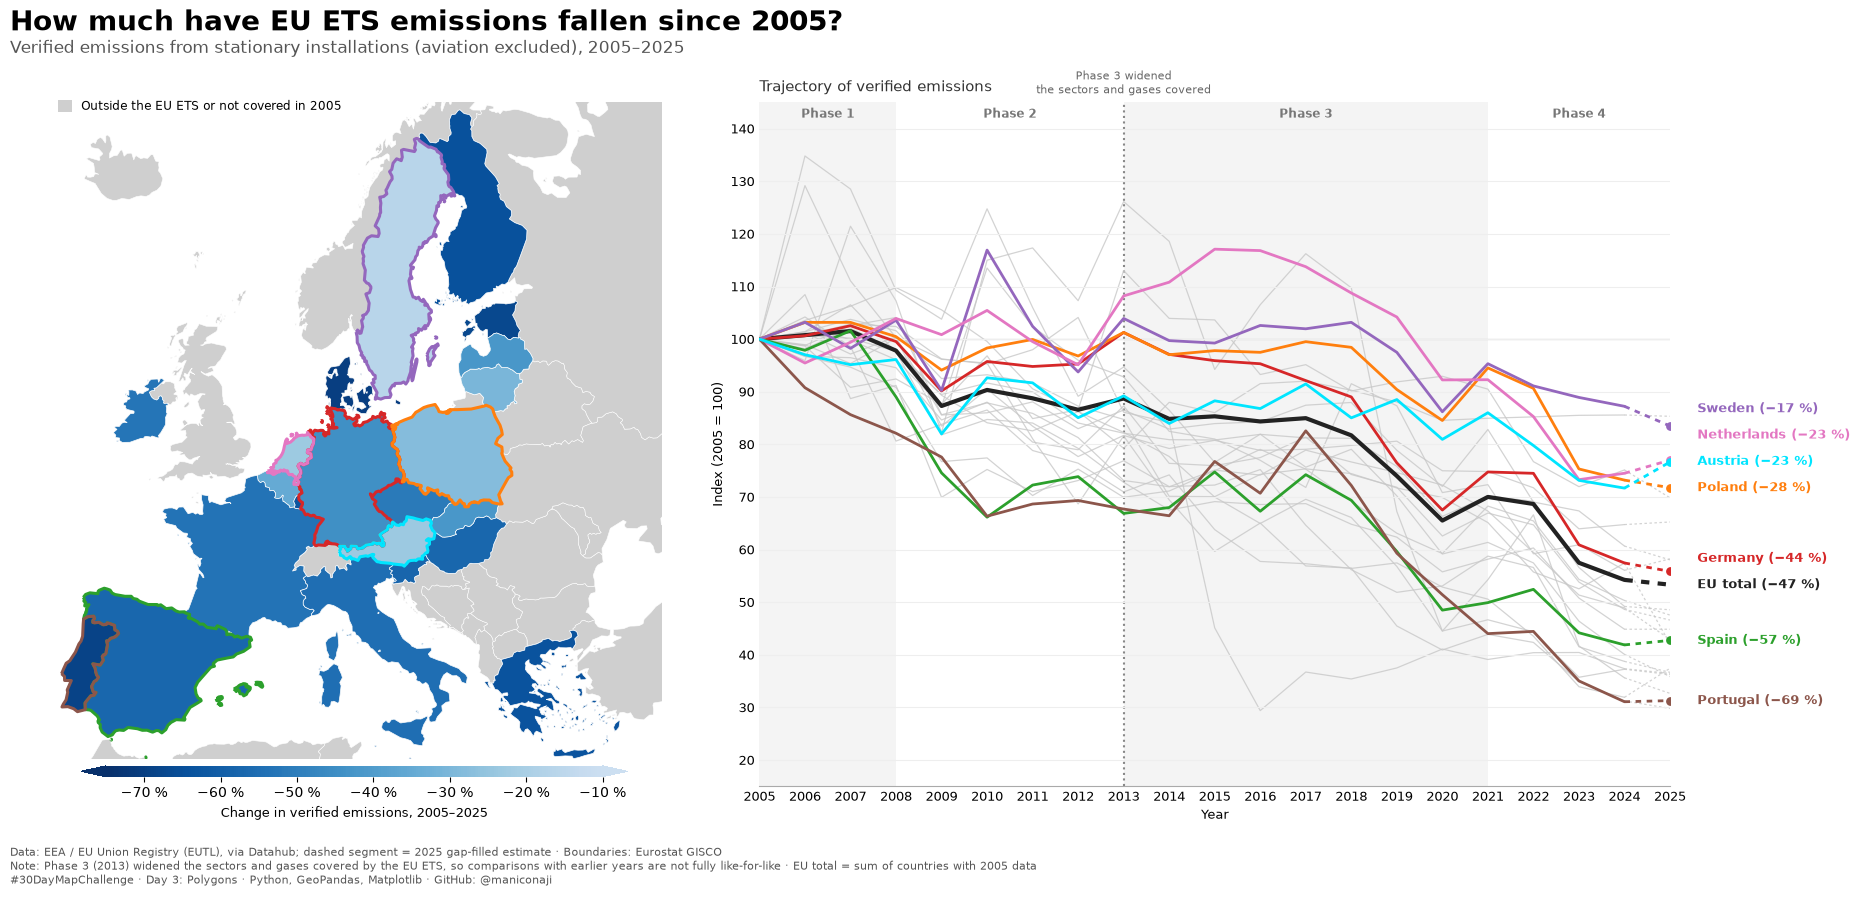

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

plt.style.use("default")

BASE, END = int(BASE_YEAR), int(END_YEAR)

# ------------------------------------------------------------------
# 1) Time series: stationary installations, verified (gap-filled for 2025)
# ------------------------------------------------------------------
d = df[df["main_activity_code"].astype(str) == "20-99"].copy()
d["year"] = pd.to_numeric(d["year"], errors="coerce")
d = d.dropna(subset=["year"])
d["year"] = d["year"].astype(int)

verified = d[(d["citl_information"] == CAT_VERIFIED) & (d["year"] < END)]
filled = d[(d["citl_information"] == CAT_FILLED) & (d["year"] == END)]
series = pd.concat([verified, filled])

pivot = series.pivot_table(index="year", columns="country_code",
                           values="value", aggfunc="sum")
pivot.columns = [("EL" if c == "GR" else c) for c in pivot.columns]

# Keep real countries only (those with a polygon) and with base-year data
pivot = pivot[[c for c in pivot.columns if c in set(world["CNTR_ID"])]]
pivot = pivot.loc[:, pivot.loc[BASE] > 0]

index = pivot.div(pivot.loc[BASE]) * 100
eu_total = pivot.sum(axis=1)
eu_index = eu_total / eu_total.loc[BASE] * 100

# ------------------------------------------------------------------
# 2) Highlighted countries
# ------------------------------------------------------------------
highlight = {
    "DE": ("Germany",    "#d62728"),
    "PL": ("Poland",     "#ff7f0e"),
    "ES": ("Spain",      "#2ca02c"),
    "SE": ("Sweden",     "#9467bd"),
    "NL": ("Netherlands","#e377c2"),
    "PT": ("Portugal",   "#8c564b"),
    "AT": ("Austria",    "#00e5ff"),
}

NBSP = "\u00a0"

# ------------------------------------------------------------------
# 3) Figure
# ------------------------------------------------------------------
fig = plt.figure(figsize=(20, 9), facecolor="white")
gs = GridSpec(1, 2, width_ratios=[1, 1.25], wspace=0.05, figure=fig)
ax_map = fig.add_subplot(gs[0])
ax_ts = fig.add_subplot(gs[1])

# ---------------- Map ----------------
norm = Normalize(vmin=-75, vmax=-10)
base_cmap = mpl.colormaps["Blues_r"]
cmap = LinearSegmentedColormap.from_list("blues_trunc", base_cmap(np.linspace(0, 0.78, 256)))


europe_chg.plot(ax=ax_map, color="#cfcfcf", edgecolor="white", linewidth=0.4)
data = europe_chg.dropna(subset=["pct"])
data.plot(column="pct", ax=ax_map, cmap=cmap, norm=norm,
          edgecolor="white", linewidth=0.5)

# Outline highlighted countries with their line colour
for code, (_, color) in highlight.items():
    sub = europe_chg[europe_chg["CNTR_ID"] == code]
    if not sub.empty:
        sub.boundary.plot(ax=ax_map, color=color, linewidth=2.2)

# Labels on the largest polygon of each country
# parts = data.explode(index_parts=False).reset_index(drop=True)
# parts["area"] = parts.geometry.area
# largest = parts.sort_values("area").groupby("country_code").tail(1).copy()
# largest["pt"] = largest.geometry.representative_point()
# for _, r in largest.iterrows():
#     txt_color = "white" if r["pct"] < -45 else "#222"
#     ax_map.annotate(f"{r['pct']:.0f}%", xy=(r["pt"].x, r["pt"].y),
#                     ha="center", va="center", fontsize=8.5,
#                     fontweight="bold", color=txt_color)

ax_map.set_xlim(2.55e6, 6.2e6)
ax_map.set_ylim(1.45e6, 5.35e6)
ax_map.set_axis_off()

ax_map.legend(
    handles=[Patch(facecolor="#cfcfcf", edgecolor="none",
                   label="Outside the EU ETS or not covered in 2005")],
    loc="upper left", bbox_to_anchor=(0.00, 1.02),
    frameon=False, fontsize=8.5, handlelength=1.2, handleheight=1.2,
)

sm = ScalarMappable(norm=norm, cmap=cmap)
cbar = fig.colorbar(sm, ax=ax_map, orientation="horizontal",
                    fraction=0.03, pad=0.01, shrink=0.75, aspect=50, extend="both")
ticks = [-70, -60, -50, -40, -30, -20, -10]
cbar.set_ticks(ticks)
cbar.set_ticklabels([f"{t}{NBSP}%".replace("-", "−") for t in ticks])
cbar.set_label(f"Change in verified emissions, {BASE}–{END}", fontsize=9)
cbar.outline.set_visible(False)

# ---------------- Time series ----------------
years = index.index.values
solid = years <= END - 1       # verified data
# last segment (END-1 -> END) is dashed because END is a gap-filled estimate

def plot_series(y, color, lw, alpha=1.0, zorder=2):
    ax_ts.plot(years[solid], y.values[solid], color=color, lw=lw,
               alpha=alpha, zorder=zorder, solid_capstyle="round")
    ax_ts.plot(years[-2:], y.values[-2:], color=color, lw=lw, alpha=alpha,
               zorder=zorder, linestyle=(0, (2, 2)))

# Background: all other countries
for c in index.columns:
    if c not in highlight:
        plot_series(index[c], "#c8c8c8", 0.9, alpha=0.8, zorder=1)

# EU total
plot_series(eu_index, "#222222", 3.0, zorder=3)

# Highlighted countries
for code, (name, color) in highlight.items():
    if code in index.columns:
        plot_series(index[code], color, 2.0, zorder=4)
        ax_ts.scatter([END], [index[code].iloc[-1]], color=color, s=28, zorder=5)

# End labels with a simple anti-overlap nudge
labels = [(index[c].iloc[-1], highlight[c][0], highlight[c][1])
          for c in highlight if c in index.columns]
labels.append((eu_index.iloc[-1], "EU total", "#222222"))
labels.sort(key=lambda t: t[0])
MIN_GAP = 5.0
ys = [l[0] for l in labels]
for i in range(1, len(ys)):
    if ys[i] - ys[i - 1] < MIN_GAP:
        ys[i] = ys[i - 1] + MIN_GAP
for (val, name, color), y_txt in zip(labels, ys):
    ax_ts.annotate(f"{name} ({val - 100:+.0f}{NBSP}%)".replace("-", "−"),
                   xy=(END, val), xytext=(END + 0.6, y_txt),
                   fontsize=9, color=color, fontweight="bold", va="center",
                   annotation_clip=False)

# ---- ETS phases as light bands ----
phases = [
    (2005, 2008, "Phase 1", "#f4f4f4"),
    (2008, 2013, "Phase 2", "#ffffff"),
    (2013, 2021, "Phase 3", "#f4f4f4"),
    (2021, 2025, "Phase 4", "#ffffff"),
]
for x0, x1, label, shade in phases:
    ax_ts.axvspan(x0, x1, color=shade, zorder=0, lw=0)
    ax_ts.text((max(x0, BASE) + x1) / 2, 144, label, ha="center", va="top",
               fontsize=8.5, color="#777", fontweight="bold")

# 2013 scope change marker
ax_ts.axvline(2013, color="#888", lw=1.5, ls=":", zorder=0)
ax_ts.text(2013, 146, "Phase 3 widened\nthe sectors and gases covered", fontsize=8,
           color="#666", va="bottom", ha="center")

ax_ts.axhline(100, color="#888", lw=0.8, zorder=0)
ax_ts.set_xticks(range(BASE, END + 1, 1))
ax_ts.set_yticks(range(10, 151, 10))
ax_ts.set_xlim(BASE, END)
ax_ts.set_ylim(15,145)
ax_ts.set_ylabel(f"Index ({BASE} = 100)", fontsize=9)
ax_ts.set_xlabel("Year", fontsize=9)
ax_ts.tick_params(labelsize=9, length=0)
ax_ts.grid(axis="y", color="#eee", lw=0.8)
for s in ("top", "right", "left"):
    ax_ts.spines[s].set_visible(False)
ax_ts.spines["bottom"].set_color("#aaa")
ax_ts.set_title("Trajectory of verified emissions", fontsize=11,
                loc="left", color="#333", pad=8)

# Leave room on the right for the end labels
fig.subplots_adjust(left=0.01, right=0.85, top=0.88, bottom=0.12)

# ---------------- Titles and footer ----------------
fig.text(0.02, 0.96, f"How much have EU ETS emissions fallen since {BASE}?",
         fontsize=20, fontweight="bold", ha="left")
fig.text(0.02, 0.935,
         f"Verified emissions from stationary installations (aviation excluded), {BASE}–{END}",
         fontsize=12, color="#555", ha="left")
fig.text(0.02, 0.012,
         f"Data: EEA / EU Union Registry (EUTL), via Datahub; dashed segment = {END} gap-filled estimate · Boundaries: Eurostat GISCO\n"
         "Note: Phase 3 (2013) widened the sectors and gases covered by the EU ETS, so comparisons with earlier years are not fully like-for-like · "
         "EU total = sum of countries with 2005 data\n"
         "#30DayMapChallenge · Day 3: Polygons · Python, GeoPandas, Matplotlib · GitHub: @maniconaji",
         fontsize=8, color="#555", ha="left", linespacing=1.25)

plt.savefig(OUT / "day03_polygons_map_timeseries.png", dpi=300,
            bbox_inches="tight", facecolor="white")
plt.show()